# Part 1: Build the Researcher Graph

In [161]:
from typing import TypedDict, Annotated
import operator
import wikipediaapi
from langchain_core.tools import tool
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage
from langgraph.graph import add_messages
from langchain_openai import ChatOpenAI
import os
from dotenv import load_dotenv
from langchain_core.messages import ToolMessage
from langgraph.graph import END, START, StateGraph
from langgraph.prebuilt import ToolNode, tools_condition
from IPython.display import Image
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings
from langchain_community.vectorstores import FAISS
from pydantic import BaseModel, Field
import json
from typing import Literal


In [162]:
load_dotenv()
API_key = os.getenv("OPENAI_API_KEY")
CHAT_MODEL = os.getenv("openai_model")
EMBED_MODEL = os.getenv("openai_embedding_model")


### Task 1: Define ResearcherState 

In [163]:
class ResearcherState (TypedDict):
    """Representing the state of a researching agent"""
    task: str 
    research: str
    messages: Annotated[list[BaseMessage], add_messages] 
    trace: Annotated[list[str], operator.add]


### Task 2: Define the Wikipedia Search Tool

In [164]:
wiki = wikipediaapi.Wikipedia(user_agent="LangGraphAssignment/1.0 (your-email@example.com)",language="en")
splitter = RecursiveCharacterTextSplitter(chunk_size=1500, chunk_overlap=200)
embedding_model = OpenAIEmbeddings(model=EMBED_MODEL, api_key=API_key)

In [165]:
@tool
def wikipedia_search(query: str):
    """ returns the top 3 Wikipedia pages for a given query. Use it when you need to gather information about a topic."""
    results = wiki.search(query, limit=3) 
    return "\n\n".join(wiki.page(title).text for title, page in results.pages.items())

### Task 3: Implement researcher_node

In [166]:
llm = ChatOpenAI(model=CHAT_MODEL, temperature=0, api_key=API_key)
tools = [wikipedia_search]
llm_with_tools=llm.bind_tools(tools)


In [167]:

def researcher_node(state: ResearcherState)-> dict: 
    prompt = "\n".join([
        "Role: You are a research agent. Gather raw information using the wikipedia_search tool. Use only the provided tool. You must not summarize or format. Output must be raw notes only. If the tool returns sufficient information about the requested topic, do not call it again.",
        f"context: {state['messages']}",
        f"task: {state['task']}"
    ])

    response = llm_with_tools.invoke([prompt]) 
    
    if state['messages'] and isinstance(state['messages'][-1], ToolMessage) :
        research_output =  state['messages'][-1].content
        return {"research":research_output, "messages":[response]}
    else:
        return {"messages":[response], "trace":["researcher"]}
    

### Task 4: Build and Compile the Researcher Graph

In [168]:
builder = StateGraph(ResearcherState)

builder.add_node("researcher", researcher_node)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "researcher")
builder.add_conditional_edges("researcher", tools_condition)
builder.add_edge("tools", "researcher")


researcher_app = builder.compile()  

### Task 5: Run the Researcher Standalone

In [169]:
query = "Search for information about generative ai?"
final_state = researcher_app.invoke(ResearcherState(task=query, messages=[HumanMessage(content=query)]))

if final_state['research'] and isinstance(final_state['research'], str) and final_state['trace'][-1]=="researcher":
    for msg in final_state['messages']:
        msg.pretty_print()
else:
    print("No pages was found on Wikipedia")

================================ Human Message =================================

Search for information about generative ai?
================================== Ai Message ==================================
Tool Calls:
  wikipedia_search (call_klda2mx6jUOSt2s3LeNGycrc)
 Call ID: call_klda2mx6jUOSt2s3LeNGycrc
  Args:
    query: generative ai
================================= Tool Message =================================
Name: wikipedia_search

Generative artificial intelligence (GenAI) is a subfield of artificial intelligence (AI) that uses generative models to generate text, images, videos, audio, computer code or other forms of digital data. These models learn the underlying patterns and structures of their training data, and use them to generate new data in response to input, which often takes the form of natural language prompts.
The prevalence of generative AI tools has increased significantly since the AI boom of the early 2020s. This boom was made possible by improvements in dee

### Task 6: Visualize the Researcher Graph

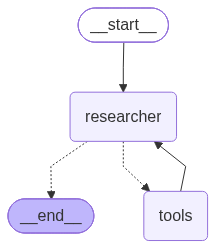

In [170]:
Image(researcher_app.get_graph().draw_mermaid_png())

# Part 2: Build the Writer Graph

### Task 1: Define WriterState

In [171]:
class WriterState (TypedDict):
    """Representing the state of a writing agent"""
    task: str 
    research: str
    feedback: str
    draft: str          # the LLM's text
    attempts: int
    messages: Annotated[list[BaseMessage], add_messages] 
    trace: Annotated[list[str], operator.add]


### Task 2: Implement writer_node

In [172]:
def writer_node(state: WriterState)-> dict:
    prompt = "\n".join([
        "Role: You are a writer agent.",
        f"Task: {state['task']}",
        f"raw source material: {state['research']}" if state["research"] else "",
        f"revision guidance: {state["feedback"] if state["feedback"] else ""}"
    ])

    response = llm_with_tools.invoke([prompt])
    return {"draft":response.content, "attempts":state["attempts"] + 1, "messages":[response], "trace":["writer"]}
    

### Task 3: Build and Compile the Writer Graph

In [173]:
builder = StateGraph(WriterState)

builder.add_node("writer", writer_node)

builder.add_edge(START, "writer")
builder.add_edge("writer", END)

writer_app = builder.compile()  

### Task 4: Run the Writer Standalone

In [174]:
result = writer_app.invoke({"task": "Write a 3-sentence pitch for a plant-watering mobile app.",
                            "research": "", "feedback": "", "draft": "", "attempts": 0,
                            "messages": [], "trace": []})

if result['draft'] and result['attempts']==1 and result['trace'][-1]=="writer":
    for msg in result['messages']:
        msg.pretty_print()
else:
    print("An error occurred while generating the draft.")

================================== Ai Message ==================================

Introducing "PlantPal," the ultimate mobile app designed to keep your plants thriving! With personalized watering schedules, reminders, and care tips tailored to each plant species, you'll never forget to hydrate your green friends again. Join a community of plant lovers, track your plant's growth, and watch your indoor jungle flourish like never before!


### Task 5: Visualize the Writer Graph

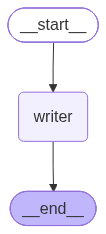

In [175]:
Image(writer_app.get_graph().draw_mermaid_png())

# Part 3: Build the Reviewer Graph

### Task 1: Define ReviewerState

In [176]:
class ReviewerState (TypedDict):
    """Representing the state of a reviewing agent"""
    task: str 
    draft: str     
    feedback: str   
    approved: bool
    messages: Annotated[list[BaseMessage], add_messages] 
    trace: Annotated[list[str], operator.add]

### Task 2: Define a Structured Output Model

In [177]:
class Review(BaseModel):
    feedback: str = Field(description="Specific, actionable feedback on the draft.")
    approved: bool = Field(description="True if the draft is good enough to publish.")

### Task 3: Implement reviewer_node

In [178]:
def reviewer_node(state: ReviewerState)-> dict:
    prompt = "\n".join([
        "Role: You are a reviewer.",
        f"Context: Task requirement '{state['task']}'",
        "Task: Review the following draft against this task requirement, and provide specific, actionable feedback. Indicate whether the draft is approved for publication.",
        f"Draft: {state['draft']}",
        "Format: Respond in the following Schema:" + json.dumps(Review.model_json_schema())
        ])

    structured_llm = llm.with_structured_output(Review)

    review: Review = structured_llm.invoke(prompt)
    
    return {
        "feedback": review.feedback,
        "approved": review.approved,
        "messages": [AIMessage(content=review.feedback)],
        "trace": ["reviewer"]
    }

### Task 4: Build and Compile the Reviewer Graph

In [179]:
builder = StateGraph(ReviewerState)

builder.add_node("reviewer", reviewer_node)

builder.add_edge(START, "reviewer")
builder.add_edge("reviewer", END)

reviewer_app = builder.compile()  

### Task 5: Run the Reviewer Standalone

In [180]:
task = "Write a slogan for a coffee shop."

result = reviewer_app.invoke({
    "task": task,
    "draft": "Coffee that wakes you up and keeps you going.",
    "feedback": "",
    "approved": False, 
    "messages": [HumanMessage(content=task)], 
    "trace": []})
    

if result['feedback'] and isinstance(result['approved'], bool) and result['trace'][-1]=="reviewer":
    for msg in result['messages']:
        msg.pretty_print()
else:
    print("An error occurred while reviewing the draft.")

================================ Human Message =================================

Write a slogan for a coffee shop.
================================== Ai Message ==================================

The draft slogan 'Coffee that wakes you up and keeps you going' effectively communicates the energizing qualities of coffee, which is a positive aspect. However, it lacks creativity and uniqueness, making it less memorable. Consider using more vivid language or a play on words to create a stronger emotional connection with potential customers. For example, something like 'Brewed for your hustle' or 'Fuel your day, one cup at a time' could be more engaging. Overall, the draft needs refinement to stand out in a competitive market.


In [181]:
result

{'task': 'Write a slogan for a coffee shop.',
 'draft': 'Coffee that wakes you up and keeps you going.',
 'feedback': "The draft slogan 'Coffee that wakes you up and keeps you going' effectively communicates the energizing qualities of coffee, which is a positive aspect. However, it lacks creativity and uniqueness, making it less memorable. Consider using more vivid language or a play on words to create a stronger emotional connection with potential customers. For example, something like 'Brewed for your hustle' or 'Fuel your day, one cup at a time' could be more engaging. Overall, the draft needs refinement to stand out in a competitive market.",
 'approved': False,
 'messages': [HumanMessage(content='Write a slogan for a coffee shop.', additional_kwargs={}, response_metadata={}, id='1280a08a-9b02-4da2-aa7d-25b38eda0b77'),
  AIMessage(content="The draft slogan 'Coffee that wakes you up and keeps you going' effectively communicates the energizing qualities of coffee, which is a positiv

### Task 6: Visualize the Reviewer Graph

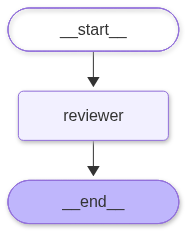

In [182]:
Image(reviewer_app.get_graph().draw_mermaid_png())

# Part 4: Build the Orchestration Layer

### Task 1: Define OrchestratorState

In [183]:
class OrchestratorState (TypedDict):
    """Representing the state of a reviewing agent"""
    task: str 
    research: str
    draft: str      # the current written draft
    feedback: str   
    approved: bool
    attempts: int
    trace: Annotated[list[str], operator.add]

### Task 2: Wrap Each Compiled Graph as a Node

In [184]:
def run_researcher(state: OrchestratorState)-> dict:
    out = researcher_app.invoke({"task": state["task"]})
    return {
    "research": out["research"],
    "trace": out["trace"],
    }


def run_writer(state: OrchestratorState)-> dict:
    out = writer_app.invoke({"task": state["task"],"research": state["research"], "feedback": state["feedback"], "attempts": state["attempts"]})
    return {
    "draft": out["draft"],
    "attempts": out["attempts"],
    "trace": out["trace"],
    } 

    
def run_reviewer(state: OrchestratorState)-> dict:
    out = reviewer_app.invoke({"task": state["task"], "draft": state["draft"]})
    return {
    "feedback": out["feedback"],
    "approved": out["approved"],
    "trace": out["trace"],
    }

### Task 3: Define the Router

In [185]:
def route_after_review(state: OrchestratorState) -> Literal["writer", END]:
    if state['approved'] == False and state['attempts'] < 2:
        return "writer"
    else:
        return END

### Task 4: Assemble & Visualize the Orchestration Graph

In [186]:
builder = StateGraph(OrchestratorState)

builder.add_node("researcher", run_researcher)
builder.add_node("writer", run_writer)
builder.add_node("reviewer", run_reviewer)

builder.add_edge(START, "researcher")
builder.add_edge("researcher", "writer")
builder.add_edge("writer", "reviewer")
builder.add_conditional_edges("reviewer", route_after_review)

multi_agent_app = builder.compile()  

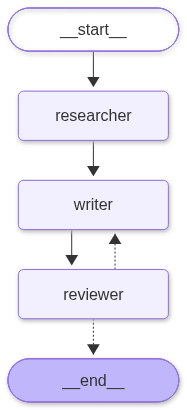

In [187]:
Image(multi_agent_app.get_graph().draw_mermaid_png())

### Task 5: Run the Orchestrated Workflow

In [188]:
Task = "Write a single-sentence slogan for a coffee shop. Keep it under 10 words."

result = multi_agent_app.invoke({"task": Task, "research": "", "draft": "", "feedback": "", "approved": False, "attempts": 0, "trace": []})

result

{'task': 'Write a single-sentence slogan for a coffee shop. Keep it under 10 words.',
 'research': 'Pocket Coffee is a brand of the Ferrero company for a chocolate confectionery, sold internationally. First marketed in Italy in 1968, each Pocket Coffee is an individually wrapped shell of dark chocolate containing liquid espresso. As with Ferrero\'s Rocher, Mon Chéri, and Raffaello, production limits sales from November to April.\nWilliam Salice, assistant to Ferrero\'s owner, Michele Ferrero, conceived the product in the early 1960s after noticing no bars at Italy\'s then relatively new Autogrills, a proprietary eponym synonymous with Italian highway rest stops. Ferrero conceived a product for anyone working long hours, e.g., truck drivers. Michele Ferrero conceived the slogan: "the energy of chocolate and the charge of coffee".\n\nIngredients\nCoffee (sweetened liquid)\nChocolate (paste)\nChocolate milk\nCocoa butter\nCocoa paste\nLactose\n\nAvailability\nPocket Coffee is sold widely 